In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

In [ ]:
# Load the processed dataset

from pathlib import Path

filename = "processed_auto_mpg.csv"
file_path = Path(filename)

if not file_path.exists():
    folder = Path("/kaggle/input")
    file_path = next(folder.rglob(filename))

df = pd.read_csv(file_path)

print("Processed Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Processed Dataset loaded successfully!
Dataset Shape: (392, 11)


,cylinders,displacement,horsepower,weight,acceleration,model year,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared,mpg
0,8,307.0,130.0,3504,12.0,70,0.037100,38.375,438.000,94249.0,18.0
1,8,350.0,165.0,3693,11.5,70,0.044679,43.750,461.625,122500.0,15.0
2,8,318.0,150.0,3436,11.0,70,0.043655,39.750,429.500,101124.0,18.0
3,8,304.0,150.0,3433,12.0,70,0.043694,38.000,429.125,92416.0,16.0
4,8,302.0,140.0,3449,10.5,70,0.040591,37.750,431.125,91204.0,17.0


In [ ]:
# Select Input Features and Target

data = df.copy()

X = data.drop(columns=["mpg"]).values
y = data["mpg"].values

print("Dataset Shape:", data.shape)

print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nSelected Features:")
print(data.drop(columns=["mpg"]).columns.tolist())

display(data.head())

Dataset Shape: (392, 11)

Input Features Shape: (392, 10)
Target Shape: (392,)

Missing Values:
cylinders                    0
displacement                 0
horsepower                   0
weight                       0
acceleration                 0
model year                   0
power_to_weight              0
displacement_per_cylinder    0
weight_per_cylinder          0
displacement_squared         0
mpg                          0
dtype: int64

Selected Features:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'power_to_weight', 'displacement_per_cylinder', 'weight_per_cylinder', 'displacement_squared']


,cylinders,displacement,horsepower,weight,acceleration,model year,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared,mpg
0,8,307.0,130.0,3504,12.0,70,0.037100,38.375,438.000,94249.0,18.0
1,8,350.0,165.0,3693,11.5,70,0.044679,43.750,461.625,122500.0,15.0
2,8,318.0,150.0,3436,11.0,70,0.043655,39.750,429.500,101124.0,18.0
3,8,304.0,150.0,3433,12.0,70,0.043694,38.000,429.125,92416.0,16.0
4,8,302.0,140.0,3449,10.5,70,0.040591,37.750,431.125,91204.0,17.0


In [ ]:
# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (313, 10)
Testing Features Shape: (79, 10)

Training Target Shape: (313,)
Testing Target Shape: (79,)


In [ ]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Add Bias Term

X_train_final = np.column_stack([
    np.ones(len(X_train_scaled)),
    X_train_scaled
])

X_test_final = np.column_stack([
    np.ones(len(X_test_scaled)),
    X_test_scaled
])

print("Feature Scaling completed successfully!")
print("Final Training Shape:", X_train_final.shape)
print("Final Testing Shape:", X_test_final.shape)

Feature Scaling completed successfully!
Final Training Shape: (313, 11)
Final Testing Shape: (79, 11)


In [ ]:
# Initialize Weights
theta = np.zeros(X_train_final.shape[1])

# Define Cost Function (MSE)
def compute_cost(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    return np.mean(errors ** 2)

# Define Gradient Function
def compute_gradient(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    gradient = (2 / len(y)) * (X.T @ errors)
    return gradient

print("Initial Weights:", theta)
print("Initial Cost:", compute_cost(X_train_final, y_train, theta))

Initial Weights: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Initial Cost: 620.0295846645367


In [ ]:
# Initialize Adam Parameters
theta_adam = np.zeros(X_train_final.shape[1])

learning_rate = 0.05
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
epochs = 3000

# Initialize First and Second Moments
m = np.zeros_like(theta_adam)
v = np.zeros_like(theta_adam)

adam_loss_history = []

# Adam Training
for epoch in range(1, epochs + 1):

    # Calculate Gradient
    gradient = compute_gradient(
        X_train_final, y_train, theta_adam
    )

    # First Moment (Momentum)
    m = beta1 * m + (1 - beta1) * gradient

    # Second Moment (Squared Gradients)
    v = beta2 * v + (1 - beta2) * (gradient ** 2)

    # Bias Correction
    m_hat = m / (1 - beta1 ** epoch)
    v_hat = v / (1 - beta2 ** epoch)

    # Update Weights
    theta_adam = theta_adam - (
        learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)
    )

    # Calculate Loss
    loss = compute_cost(
        X_train_final, y_train, theta_adam
    )

    adam_loss_history.append(loss)

print("Adam Training Completed!")
print("Final Weights:", theta_adam)
print("Final Training MSE:", adam_loss_history[-1])

Adam Training Completed!
Final Weights: [23.59936102 -6.6107671  -3.68018583  2.10435811 -1.66922419 -0.40536774
  2.8387106  -2.03366128 -2.09001845 -2.38552719  6.26147049]
Final Training MSE: 8.336352863924725


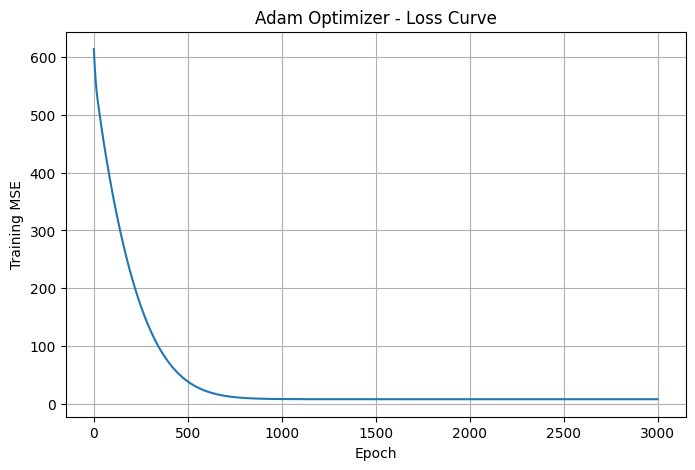

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(adam_loss_history)

plt.title("Adam Optimizer - Loss Curve")

plt.xlabel("Epoch")
plt.ylabel("Training MSE")

plt.grid(True)
plt.show()

In [ ]:
# Make Predictions
y_pred = X_test_final @ theta_adam

# Calculate Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Adam Model Evaluation")
print("---------------------")
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2 Score:", r2)

Adam Model Evaluation
---------------------
Test MSE: 8.946623539685518
Test RMSE: 2.9910906939919957
Test R2 Score: 0.8247154916384707


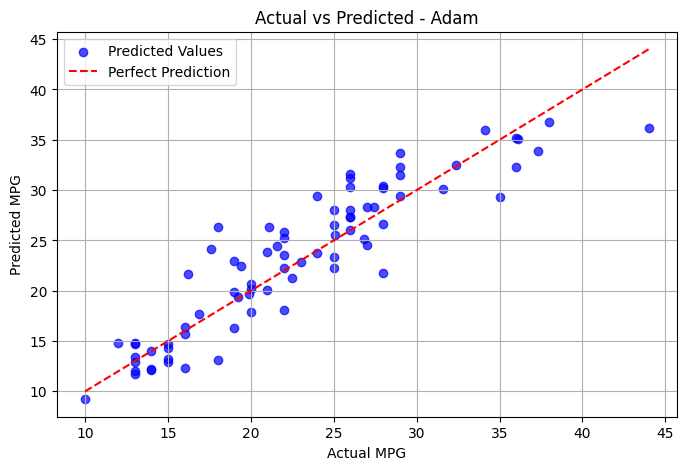

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test, y_pred,
    color="blue",
    alpha=0.7,
    label="Predicted Values"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted - Adam")

plt.legend()
plt.grid(True)
plt.show()